# Week 06: IPO & distribution shapes — **self-paced**

**Course:** MATH7810 Python for Data Science (AY2026/27)  
Work through the tasks **in order**. The instructor will **walk around**. Ask if you are stuck after the “If you are stuck” steps.

**This notebook:** Binomial shape, standardizing $Z$, continuity correction, Normal quantile.  


## How to work today

| Step | What you do |
|------|----------------|
| 1 | Read the **task**. |
| 2 | Complete or use the **IPO** comments. |
| 3 | **`Cmd+I` / `Ctrl+I`** → implement comments → **Keep**. |
| 4 | **Read** the code → **Shift+Enter**. |
| 5 | Type the short note and **run** it. |

**If stuck:** Setup ran? Process filled? Then ask — bring what you tried.

## A. IPO reminder

Same habit as Week 5. **Input → Process → Output. AI drafts; **you** verify. The same prompt can differ across runs.


## Setup — run this **first**

**Done when:** the cell prints `Ready` with no error.


In [1]:
# Setup — run this cell first
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binom, norm, expon  # short names for Binomial, Normal, Exponential

rng = np.random.default_rng(42)  # reproducible draws for the sim tasks
print("Ready. numpy", np.__version__)  # prints which NumPy you have; __version__ is the name of that version label


Ready. numpy 2.5.2


## Task 1 — Binomial shape vs \(p\)

**Question:** How does the shape of a Binomial distribution differ for different values of \(p\)?

Keep **\(n = 10\)** fixed. Only **\(p\)** changes: **0.2**, **0.5**, **0.9**.

Fill **Process** and **Output**, then Inline Chat.

**Done when:** three bar charts in a row + 1–2 sentences on skewness.

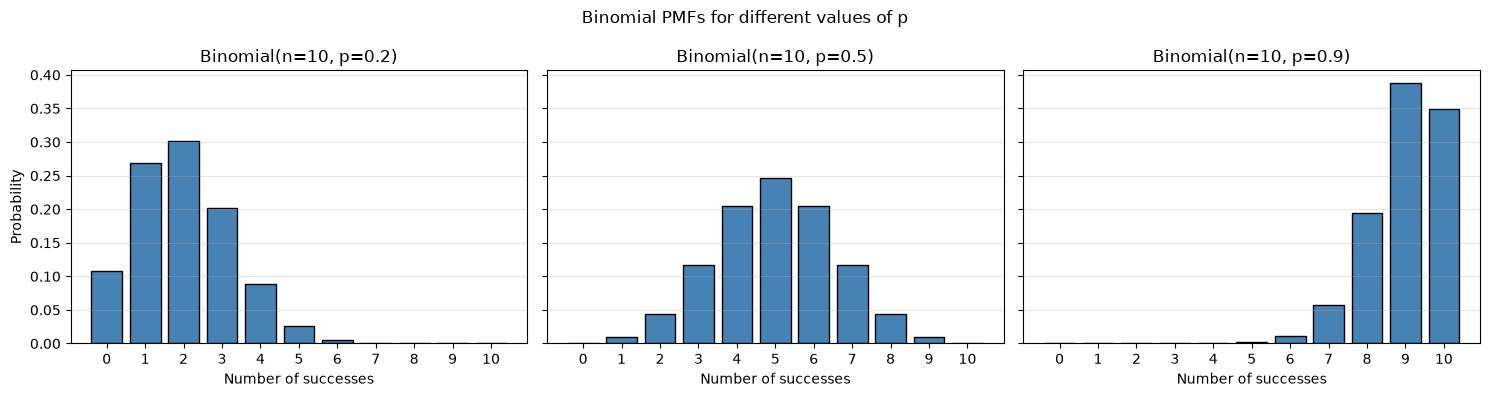

In [2]:
# Task 1 — Binomial PMFs in a row (fixed n, three p)
# --- Write your AI prompt here (Input → Process → Output) ---
# Input: scipy.stats.binom and matplotlib.pyplot.
#
# Process: Create Binomial PMFs for n=10 and p values 0.2, 0.5, and 0.9. Plot the three PMFs as side-by-side bar charts with a shared x-axis and clear titles and labels.
#
# Output: Three bar charts in one row showing the probability of each count from 0 through 10.
#
# --- End prompt ---
# Fill Process + Output from the task (3 PMFs side by side). Then Inline Chat.
#
# --- generated / your code below ---
n = 10
p_values = [0.2, 0.5, 0.9]
x = np.arange(n + 1)
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

for ax, p in zip(axes, p_values):
    ax.bar(x, binom.pmf(x, n, p), color="steelblue", edgecolor="black")
    ax.set_title(f"Binomial(n={n}, p={p})")
    ax.set_xlabel("Number of successes")
    ax.set_xticks(x)
    ax.grid(axis="y", alpha=0.3)

axes[0].set_ylabel("Probability")
fig.suptitle("Binomial PMFs for different values of p")
fig.tight_layout()
plt.show()


**Check:** Does the output make sense? Why? Type in the next cell, then **run** it.


In [3]:
# Task 1 — write BETWEEN the triple quotes, then RUN
task1_skew = """
# Skewness (p = 0.2 / 0.5 / 0.9):

When p = 0.2, the distribution is right-skewed; when p = 0.5, it is approximately symmetric; and when p = 0.9, it is left-skewed. The distribution is concentrated near 0 successes for p = 0.2 and near 10 successes for p = 0.9.
"""
print(task1_skew)



# Skewness (p = 0.2 / 0.5 / 0.9):

When p = 0.2, the distribution is right-skewed; when p = 0.5, it is approximately symmetric; and when p = 0.9, it is left-skewed. The distribution is concentrated near 0 successes for p = 0.2 and near 10 successes for p = 0.9.



## Task 2 — Standardizing does **not** create a Normal

**Question:** If we rescale a variable so it has mean 0 and variance 1, is the result always Normal?

Lecture: $Z = (X-\mu)/\sigma$ has **mean 0** and **variance 1**, but is Normal **only if** $X$ is Normal.

Let $X$ be **Exponential** (scale $= 2$). Draw 10,000 values, form $Z$, print mean/var of $Z$, histogram $X$ and $Z$, overlay $N(0,1)$ on $Z$.

Fill **Process** and **Output**, then Inline Chat.

**Done when:** mean of $Z$ is about $0$, variance about $1$, but $Z$ still looks **skewed**.


Mean of Z: -0.0000
Variance of Z: 1.0000


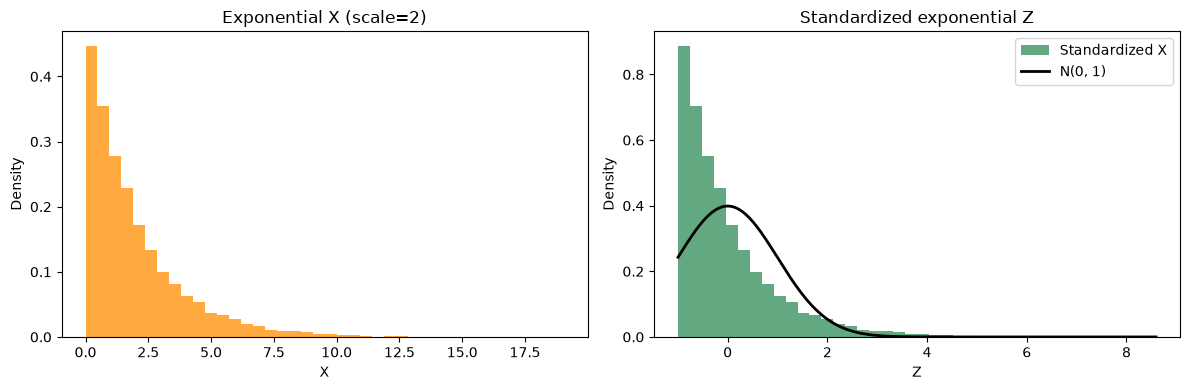

In [4]:
# Task 2 — Standardize a non-Normal X
# --- Write your AI prompt here (Input → Process → Output) ---
# Input: numpy, matplotlib.pyplot, rng, and scipy.stats.expon and scipy.stats.norm
#   are already available. 
# Process: Draw 10,000 observations from an Exponential distribution with scale=2 using rng, standardize them with their sample mean and standard deviation, and calculate the mean and variance of Z. Plot histograms of X and Z, and overlay the N(0,1) density on the Z histogram.
#
# Output: Printed mean and variance for Z, plus histograms showing that Z is still right-skewed even though its mean is about 0 and variance is about 1.
#
# --- End prompt ---
# Fill Process + Output, then Inline Chat. Read the code before running.
#
# --- generated / your code below ---
x_exp = rng.exponential(scale=2, size=10_000)
z = (x_exp - x_exp.mean()) / x_exp.std()
print(f"Mean of Z: {z.mean():.4f}")
print(f"Variance of Z: {z.var():.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(x_exp, bins=40, density=True, color="darkorange", alpha=0.75)
axes[0].set_title("Exponential X (scale=2)")
axes[0].set_xlabel("X")
axes[0].set_ylabel("Density")
axes[1].hist(z, bins=40, density=True, color="seagreen", alpha=0.75, label="Standardized X")
z_grid = np.linspace(z.min(), z.max(), 400)
axes[1].plot(z_grid, norm.pdf(z_grid), color="black", linewidth=2, label="N(0, 1)")
axes[1].set_title("Standardized exponential Z")
axes[1].set_xlabel("Z")
axes[1].set_ylabel("Density")
axes[1].legend()
fig.tight_layout()
plt.show()


**Check:** mean/var of \(Z\) vs **shape** of \(Z\). Type 1–2 sentences in the next cell, then run it.


In [5]:
# Task 2 — write BETWEEN the triple quotes, then RUN
task5_z = """
# Mean/var of Z vs shape of Z:

Standardizing makes the mean of Z approximately 0 and its variance approximately 1, but it does not change the underlying right-skewed shape into a Normal distribution. The histogram of Z still differs from the overlaid N(0,1) curve.
"""
print(task5_z)



# Mean/var of Z vs shape of Z:

Standardizing makes the mean of Z approximately 0 and its variance approximately 1, but it does not change the underlying right-skewed shape into a Normal distribution. The histogram of Z still differs from the overlaid N(0,1) curve.



## Task 3 — Normal approximation and continuity correction

**Question:** A Binomial count is a whole number; a Normal curve is continuous. Why do we need a continuity correction when we approximate Binomial probabilities with a Normal?

Each Binomial bar sits on an integer and has **width 1**. The matching Normal area for that bar is from half a unit below to half a unit above — a **continuity correction**.

**Example**: **$n = 16$**, **$p = 0.5$**, so $np = 8 > 5$ and $n(1-p) = 8 > 5$. Let $X$ be Binomial; let $Y$ be Normal with the same mean $np$ and sd $\sqrt{np(1-p)}$.

1. Plot the Binomial PMF bars and overlay the Normal curve.
2. Print three values of $P(X \le 6)$: 
- exact Binomial; 
- Normal **without** correction ($Y \le 6$); 
- Normal **with** correction ($Y \le 6.5$).

Fill **Process** and **Output**, then Inline Chat.

**Done when:** one plot and three printed probabilities. If it helps, add vertical lines at 6 and 6.5 so the half-unit gap is easy to see.


Exact Binomial P(X <= 6): 0.227249
Normal without correction P(Y <= 6): 0.158655
Normal with correction P(Y <= 6.5): 0.226627


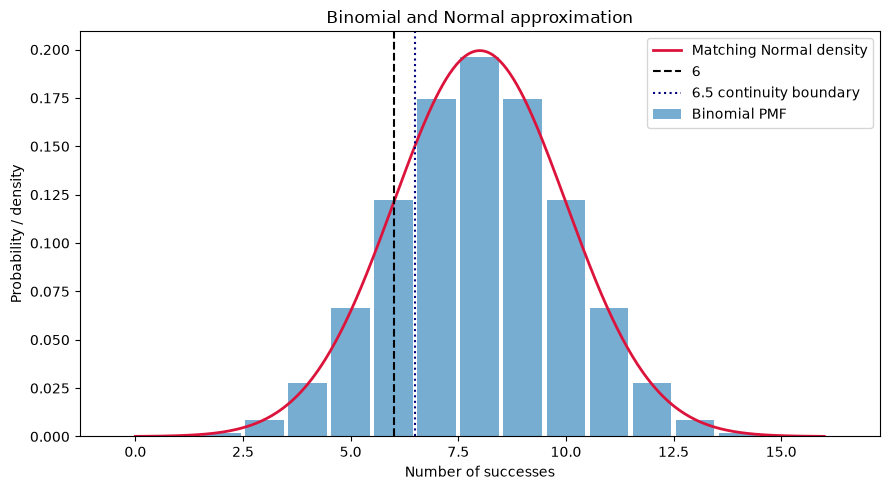

In [6]:
# Task 3 — Normal approx. + continuity correction
# --- Write your AI prompt here (Input → Process → Output) ---
# Input: numpy, matplotlib.pyplot, scipy.stats.binom and scipy.stats.norm
#   are already imported.
# Process: Set n=16 and p=0.5, calculate the exact Binomial probability P(X <= 6), calculate the Normal approximation without continuity correction using Y <= 6, and calculate it with continuity correction using Y <= 6.5. Plot the Binomial PMF bars and the matching Normal density, with vertical lines at 6 and 6.5.
#
# Output: One PMF-and-Normal plot and the three probabilities printed with clear labels.
#
# --- End prompt ---
# Fill Process + Output, then Inline Chat. Read the code before running.
#
# --- generated / your code below ---
n_cc = 16
p_cc = 0.5
mu_cc = n_cc * p_cc
sigma_cc = np.sqrt(n_cc * p_cc * (1 - p_cc))
x_cc = np.arange(n_cc + 1)
exact_prob = binom.cdf(6, n_cc, p_cc)
normal_no_cc = norm.cdf(6, loc=mu_cc, scale=sigma_cc)
normal_with_cc = norm.cdf(6.5, loc=mu_cc, scale=sigma_cc)
print(f"Exact Binomial P(X <= 6): {exact_prob:.6f}")
print(f"Normal without correction P(Y <= 6): {normal_no_cc:.6f}")
print(f"Normal with correction P(Y <= 6.5): {normal_with_cc:.6f}")

y_grid = np.linspace(mu_cc - 4 * sigma_cc, mu_cc + 4 * sigma_cc, 400)
fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(x_cc, binom.pmf(x_cc, n_cc, p_cc), width=0.9, alpha=0.6, label="Binomial PMF")
ax.plot(y_grid, norm.pdf(y_grid, loc=mu_cc, scale=sigma_cc), color="crimson", linewidth=2, label="Matching Normal density")
ax.axvline(6, color="black", linestyle="--", label="6")
ax.axvline(6.5, color="navy", linestyle=":", label="6.5 continuity boundary")
ax.set_xlabel("Number of successes")
ax.set_ylabel("Probability / density")
ax.set_title("Binomial and Normal approximation")
ax.legend()
fig.tight_layout()
plt.show()


**Check:** which Normal probability is closer to the exact Binomial $P(X \le 6)$? Type in the next cell, then run it.


In [7]:
# Task 3 — write BETWEEN the triple quotes, then RUN
task3_cc = """
# Which Normal value is closer, and why add 0.5:

The Normal probability with the continuity correction is closer to the exact Binomial probability. Adding 0.5 uses the interval from negative infinity to 6.5 to represent the whole-number outcomes through 6, matching the width-1 Binomial bars more closely.
"""
print(task3_cc)



# Which Normal value is closer, and why add 0.5:

The Normal probability with the continuity correction is closer to the exact Binomial probability. Adding 0.5 uses the interval from negative infinity to 6.5 to represent the whole-number outcomes through 6, matching the width-1 Binomial bars more closely.



## Task 4 — Normal quantile from a probability

**Question:** In lecture we read a $z$-table *backwards*: given an area, find $z_0$. How do we do that in Python?

Lecture example: find $z_0$ if $P(Z < z_0) = 0.75$ (table: about $0.67$).

`scipy.stats.norm.ppf` is the inverse of `norm.cdf`: given a left-tail probability, it returns the cut-off.

Fill **Process** and **Output**, then Inline Chat.

**Done when:** the printed $z_0$ is close to $0.67$.


In [8]:
# Task 4 — Normal quantile (ppf)
# --- Write your AI prompt here (Input → Process → Output) ---
# Input: scipy.stats.norm is already imported.
# Process: Use norm.ppf to find the z value whose left-tail probability is 0.75.
#
# Output: Print z0, which should be approximately 0.6745 and therefore close to the lecture table value 0.67.
#
# --- End prompt ---
# Fill Process + Output, then Inline Chat. Read the code before running.
#
# --- generated / your code below ---
probability = 0.75
z0 = norm.ppf(probability)
print(f"z0 for P(Z < z0) = {probability}: {z0:.4f}")


z0 for P(Z < z0) = 0.75: 0.6745


**Check:** is the printed $z_0$ close to the lecture table value $0.67$? Type in the next cell, then run it.


## Before you leave — checklist
- [x] Setup ran  
- [x] **Task 1:** three Binomial PMFs + skewness note  
- [x] **Task 2:** \(Z\) mean 0, var 1, still not Normal  
- [x] **Task 3:** $P(X \le 6)$ exact vs Normal without/with $+0.5$ ($n=16$, $p=0.5$); you can say **why** we correct  
- [x] **Task 4:** $z_0$ for $P(Z<z_0)=0.75$ via `norm.ppf` (about $0.67$)  
